<a href="https://colab.research.google.com/github/annisa24ti-dev/Probabilitas-dan-Distribusi-Probabilitas/blob/main/Probabilitas_Statistika_Annisa_Desriani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



**Annisa Desriani | NIM 2455301027 | Kelas 3 TI B**

## 0. Persiapan library

In [ ]:
# Jika diperlukan, jalankan:
# %pip install numpy scipy pandas matplotlib sympy scikit-learn

import math, random, hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from scipy import stats

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Library siap digunakan.")
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

Library siap digunakan.
NumPy: 2.4.6 | pandas: 2.2.3


## BAB III – Eksplorasi Library Python

### 3.1 random, statistics, math, dan itertools

In [ ]:
import statistics
import itertools

random.seed(SEED)
dadu = [random.randint(1, 6) for _ in range(1000)]
print("Mean:", statistics.mean(dadu))
print("Median:", statistics.median(dadu))
print("Varians sampel:", statistics.variance(dadu))
print("Kombinasi C(5,2):", math.comb(5, 2))
print("Permutasi P(5,2):", math.perm(5, 2))
print("Faktorial 5:", math.factorial(5))
print("Kombinasi [1,2,3]:", list(itertools.combinations([1,2,3], 2)))

Mean: 3.506
Median: 3.5
Varians sampel: 2.9629269269269267
Kombinasi C(5,2): 10
Permutasi P(5,2): 20
Faktorial 5: 120
Kombinasi [1,2,3]: [(1, 2), (1, 3), (2, 3)]


### 3.2 NumPy

In [ ]:
data = np.random.binomial(30, 0.08, 500_000)
print("Mean:", data.mean(), "Varians:", data.var(), "SD:", data.std())
print("Contoh Poisson:", np.random.poisson(5, 10))
print("Contoh Eksponensial:", np.random.exponential(1/5, 10))
print("Contoh Normal:", np.random.normal(120, 15, 10))
print("Contoh Uniform:", np.random.uniform(5, 25, 10))

Mean: 2.401044 Varians: 2.2053517100639994 SD: 1.4850426627083815
Contoh Poisson: [7 5 4 7 3 2 4 2 7 5]
Contoh Eksponensial: [0.29117741 0.09303751 0.16267767 0.42136674 0.10748231 0.14769548
 0.01159599 0.10228593 0.6105     0.15507668]
Contoh Normal: [115.07347917 153.0157481  109.28810696 119.57176894 131.40408918
  94.71776773 130.14121457 148.45120368 121.38088273 102.45934477]
Contoh Uniform: [14.51935377 17.35976796 19.40587245 10.68339477 21.44882964  5.89428638
 16.64597186 17.34179382 15.28098187 14.79188611]


### 3.3 SciPy (scipy.stats)

In [ ]:
X = stats.binom(30, 0.08)
print("PMF P(X=2):", X.pmf(2))
print("CDF P(X<=3):", X.cdf(3))
print("SF P(X>=5):", X.sf(4))
print("Mean:", X.mean(), "Varians:", X.var(), "SD:", X.std())
print("Sampel:", X.rvs(size=10, random_state=SEED))

PMF P(X=2): 0.2696052820880312
CDF P(X<=3): 0.7842064485762474
SF P(X>=5): 0.08736154558975634
Mean: 2.4 Varians: 2.2079999999999997 SD: 1.4859340496805367
Sampel: [2 5 3 3 1 1 0 4 3 3]


### 3.4 pandas dan Matplotlib

,Modul,Kritis,Non-kritis
0,Auth,12,188
1,Payment,25,175
2,UI,8,292


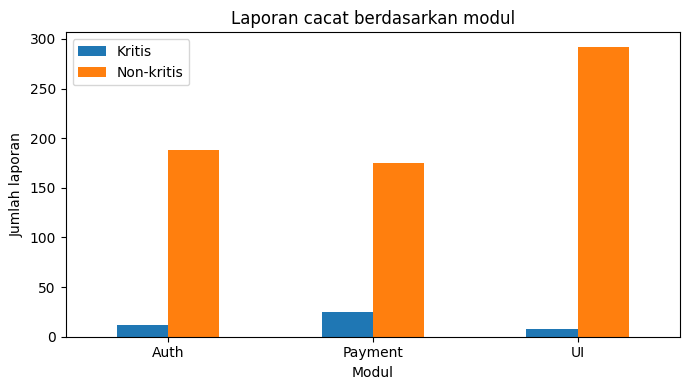

In [ ]:
df_contoh = pd.DataFrame({
    "Modul": ["Auth", "Payment", "UI"],
    "Kritis": [12, 25, 8],
    "Non-kritis": [188, 175, 292]
})
display(df_contoh)
df_contoh.plot(x="Modul", y=["Kritis", "Non-kritis"], kind="bar", figsize=(7,4))
plt.title("Laporan cacat berdasarkan modul")
plt.ylabel("Jumlah laporan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.5 scikit-learn dan SymPy

In [ ]:
docs = ["gratis hadiah klik", "gratis pulsa klik", "rapat besok jam", "tugas besok kumpul"]
labels = ["spam", "spam", "ham", "ham"]
vec = CountVectorizer()
X = vec.fit_transform(docs)
model = MultinomialNB(alpha=1).fit(X, labels)
print("Kosakata:", vec.get_feature_names_out())
print("Probabilitas pesan baru:", model.predict_proba(vec.transform(["gratis klik besok"])))

pr = sp.symbols("pr")
hasil = sp.simplify(
    sp.Rational(99,100)*pr /
    (sp.Rational(99,100)*pr + sp.Rational(2,100)*(1-pr))
)
print("Hasil simbolik Bayes:", hasil)

Kosakata: ['besok' 'gratis' 'hadiah' 'jam' 'klik' 'kumpul' 'pulsa' 'rapat' 'tugas']
Probabilitas pesan baru: [[0.25 0.75]]
Hasil simbolik Bayes: 99*pr/(97*pr + 2)


## BAB IV – Implementasi dan Analisis Permasalahan Probabilitas

### 4.1 P1: Probabilitas dasar dan komplemen pada kode OTP

In [ ]:
n = 10**6
jumlah_permutasi = math.perm(10, 6)
p_tebak_1 = 1/n
p_tebak_3 = 1-(1-1/n)**3
p_semua_berbeda = jumlah_permutasi/n
p_berulang = 1-p_semua_berbeda

print("P(tebak OTP 1 kali) =", p_tebak_1)
print("P(berhasil dalam 3 percobaan berbeda) =", p_tebak_3)
print("P(semua digit berbeda) =", p_semua_berbeda)
print("P(setidaknya satu digit berulang) =", p_berulang)

N_OTP = 200_000
sim_otp = np.mean([len(set(np.random.randint(0,10,6))) < 6 for _ in range(N_OTP)])
print("Simulasi digit berulang =", sim_otp)

P(tebak OTP 1 kali) = 1e-06
P(berhasil dalam 3 percobaan berbeda) = 2.99999700004161e-06
P(semua digit berbeda) = 0.1512
P(setidaknya satu digit berulang) = 0.8488
Simulasi digit berulang = 0.848975


### 4.2 P2: Kombinasi kejadian pada ketersediaan server

In [ ]:
p = np.array([0.95, 0.90, 0.98])
semua_aktif = p.prod()
minimal_satu = 1-(1-p).prod()
tepat_satu = sum(p[i]*np.prod([1-p[j] for j in range(3) if j != i]) for i in range(3))

print("P(semua aktif) =", semua_aktif)
print("P(minimal satu aktif) =", minimal_satu)
print("P(tepat satu aktif) =", tepat_satu)

N_SERVER = 1_000_000
S = np.random.rand(N_SERVER, 3) < p
sim_semua = S.all(axis=1).mean()
sim_minimal = S.any(axis=1).mean()
sim_tepat_satu = (S.sum(axis=1)==1).mean()
print("Simulasi semua aktif =", sim_semua)
print("Simulasi minimal satu aktif =", sim_minimal)
print("Simulasi tepat satu aktif =", sim_tepat_satu)

P(semua aktif) = 0.8379
P(minimal satu aktif) = 0.9999
P(tepat satu aktif) = 0.0077000000000000055
Simulasi semua aktif = 0.838118
Simulasi minimal satu aktif = 0.9999
Simulasi tepat satu aktif = 0.007612


### 4.3 P3: Probabilitas bersyarat pada laporan cacat perangkat lunak

,Kritis,Non-kritis,Total
Auth,12,188,200
Payment,25,175,200
UI,8,292,300


P(Kritis) = 0.06428571428571428
P(Kritis | Payment) = 0.125
P(Payment | Kritis) = 0.5555555555555556
P(Payment)*P(Kritis) = 0.01836734693877551
P(Payment dan Kritis) = 0.03571428571428571
Chi-square = 19.375176703420973 | p-value = 6.204886416052282e-05 | df = 2
Independen pada alpha 0.05? False


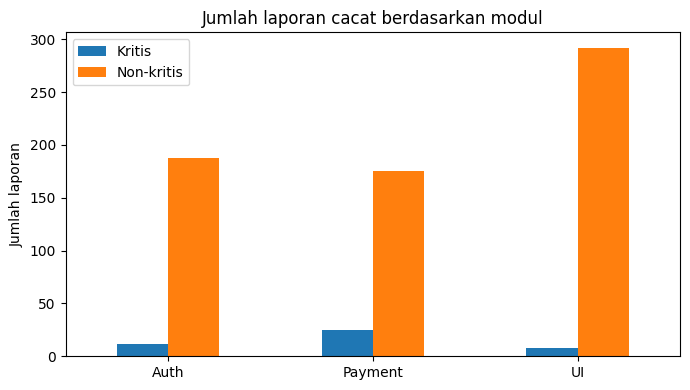

In [ ]:
df_bug = pd.DataFrame(
    {"Kritis":[12,25,8], "Non-kritis":[188,175,292]},
    index=["Auth","Payment","UI"]
)
df_bug["Total"] = df_bug.sum(axis=1)
display(df_bug)

p_kritis = 45/700
p_kritis_payment = 25/200
p_payment_kritis = 25/45
p_payment = 200/700
p_irisan = 25/700
p_produk = p_payment*p_kritis

print("P(Kritis) =", p_kritis)
print("P(Kritis | Payment) =", p_kritis_payment)
print("P(Payment | Kritis) =", p_payment_kritis)
print("P(Payment)*P(Kritis) =", p_produk)
print("P(Payment dan Kritis) =", p_irisan)

chi2, pvalue, dof, expected = stats.chi2_contingency(df_bug[["Kritis","Non-kritis"]])
print("Chi-square =", chi2, "| p-value =", pvalue, "| df =", dof)
print("Independen pada alpha 0.05?", pvalue >= 0.05)

df_bug[["Kritis","Non-kritis"]].plot(kind="bar", figsize=(7,4))
plt.title("Jumlah laporan cacat berdasarkan modul")
plt.ylabel("Jumlah laporan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.4 P4: Teorema Bayes pada alert sistem deteksi intrusi (IDS)

In [ ]:
prior, tpr, fpr = 0.001, 0.99, 0.02
p_alert = tpr*prior + fpr*(1-prior)
posterior = tpr*prior/p_alert

# Alert kedua diasumsikan independen secara bersyarat dari alert pertama,
# dengan sensitivitas dan false-positive rate yang sama.
posterior_2 = (tpr*posterior)/(tpr*posterior + fpr*(1-posterior))

print("P(Alert) =", p_alert)
print("P(Serangan | 1 alert) =", posterior)
print("P(Serangan | 2 alert) =", posterior_2)

M = 3_000_000
att = np.random.rand(M) < prior
alert = np.where(att, np.random.rand(M)<tpr, np.random.rand(M)<fpr)
sim_ids = att[alert].mean()
print("Simulasi P(Serangan | alert) =", sim_ids)

pr = sp.symbols("pr")
print("Posterior simbolik =", sp.simplify(
    sp.Rational(99,100)*pr /
    (sp.Rational(99,100)*pr + sp.Rational(2,100)*(1-pr))
))

P(Alert) = 0.020970000000000003
P(Serangan | 1 alert) = 0.047210300429184546
P(Serangan | 2 alert) = 0.710371819960861
Simulasi P(Serangan | alert) = 0.04876691418485952
Posterior simbolik = 99*pr/(97*pr + 2)


### 4.5 P5: Simulasi dan probabilitas empiris pada tabrakan hash

k=100: eksak=0.072784; aproksimasi=0.072749
k=300: eksak=0.496112; aproksimasi=0.495585
k=500: eksak=0.851681; aproksimasi=0.850959
Simulasi MD5 mod 2^16, k=300 = 0.512
Perkiraan median k = 301.4144


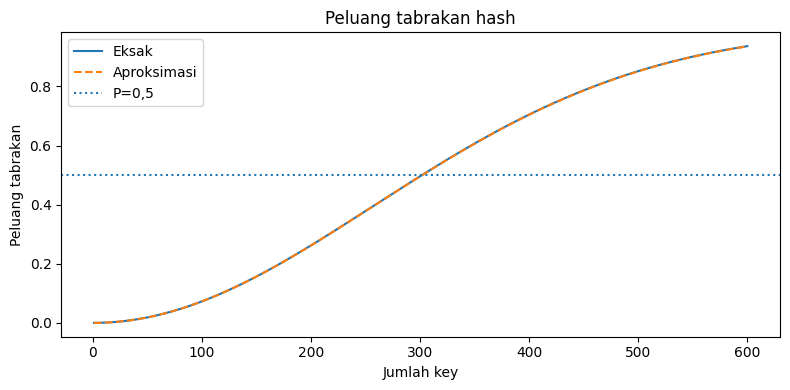

In [ ]:
m = 2**16

def peluang_tabrakan_eksak(k, m):
    log_p_tidak = sum(math.log1p(-i/m) for i in range(k))
    return 1-math.exp(log_p_tidak)

def peluang_tabrakan_approx(k, m):
    return 1-math.exp(-k*(k-1)/(2*m))

def trial_hash(k, m=m):
    seen = set()
    for _ in range(k):
        h = hashlib.md5(f"user{random.random()}".encode()).hexdigest()
        slot = int(h, 16) % m
        if slot in seen:
            return True
        seen.add(slot)
    return False

for k in [100,300,500]:
    print(f"k={k}: eksak={peluang_tabrakan_eksak(k,m):.6f}; "
          f"aproksimasi={peluang_tabrakan_approx(k,m):.6f}")

N_HASH = 2000
sim_hash = np.mean([trial_hash(300) for _ in range(N_HASH)])
print("Simulasi MD5 mod 2^16, k=300 =", sim_hash)
print("Perkiraan median k =", 1.1774*math.sqrt(m))

ks = np.arange(1,601)
plt.figure(figsize=(8,4))
plt.plot(ks, [peluang_tabrakan_eksak(int(k),m) for k in ks], label="Eksak")
plt.plot(ks, [peluang_tabrakan_approx(int(k),m) for k in ks], "--", label="Aproksimasi")
plt.axhline(0.5, linestyle=":", label="P=0,5")
plt.title("Peluang tabrakan hash")
plt.xlabel("Jumlah key")
plt.ylabel("Peluang tabrakan")
plt.legend()
plt.tight_layout()
plt.show()

### 4.6 P6a: Perhitungan Naive Bayes secara manual dan scikit-learn

In [ ]:
docs = ["gratis hadiah klik", "gratis pulsa klik", "rapat besok jam", "tugas besok kumpul"]
y = ["spam", "spam", "ham", "ham"]
pesan = "gratis klik besok"

vocab = sorted(set(" ".join(docs).split()))
V = len(vocab)
counter_spam = Counter(w for d,l in zip(docs,y) if l=="spam" for w in d.split())
counter_ham = Counter(w for d,l in zip(docs,y) if l=="ham" for w in d.split())
total_spam = sum(len(d.split()) for d,l in zip(docs,y) if l=="spam")
total_ham = sum(len(d.split()) for d,l in zip(docs,y) if l=="ham")
prior_spam = y.count("spam")/len(y)
prior_ham = y.count("ham")/len(y)

score_spam, score_ham = prior_spam, prior_ham
for word in pesan.split():
    score_spam *= (counter_spam[word]+1)/(total_spam+V)
    score_ham *= (counter_ham[word]+1)/(total_ham+V)

p_spam = score_spam/(score_spam+score_ham)
p_ham = score_ham/(score_spam+score_ham)
print("Vocabulary:", vocab, "|V| =", V)
print("Skor spam =", score_spam, "| Skor ham =", score_ham)
print("P(spam | pesan) =", p_spam)
print("P(ham | pesan) =", p_ham)

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(docs)
clf = MultinomialNB(alpha=1).fit(X,y)
print("Sklearn probabilities =", clf.predict_proba(vectorizer.transform([pesan])))
print("Prediksi =", clf.predict(vectorizer.transform([pesan])))

Vocabulary: ['besok', 'gratis', 'hadiah', 'jam', 'klik', 'kumpul', 'pulsa', 'rapat', 'tugas'] |V| = 9
Skor spam = 0.0013333333333333335 | Skor ham = 0.00044444444444444447
P(spam | pesan) = 0.7500000000000001
P(ham | pesan) = 0.25
Sklearn probabilities = [[0.25 0.75]]
Prediksi = ['spam']


### 4.6 P6b: Klasifikasi SMS Spam Collection
Notebook akan memakai `SMSSpamCollection` jika tersedia. Jika tidak, dibuat data sintetis demonstrasi. Perhatikan label sumber data pada output.

In [ ]:
def load_sms():
    candidates = [Path("SMSSpamCollection"), Path("SMSSpamCollection.txt"),
                  Path("data/SMSSpamCollection")]
    for path in candidates:
        if path.exists():
            data = pd.read_csv(path, sep="\\t", header=None,
                               names=["label","text"], encoding="latin-1")
            data = data.dropna()
            data["label"] = data["label"].str.lower().str.strip()
            data = data[data["label"].isin(["ham","spam"])]
            if len(data):
                return data, f"Dataset asli: {path}"

    spam_templates = [
        "gratis hadiah klik tautan sekarang", "selamat anda menang hadiah gratis",
        "klaim bonus pulsa gratis hari ini", "promo khusus klik untuk hadiah",
        "anda mendapat voucher gratis segera klaim"
    ]
    ham_templates = [
        "rapat besok dimulai pukul sembilan", "jangan lupa kumpulkan tugas kuliah",
        "saya sedang menuju kampus sekarang", "nanti kita belajar bersama",
        "tolong kirim catatan perkuliahan hari ini"
    ]
    texts, labels = [], []
    for i in range(300):
        texts.append(spam_templates[i % len(spam_templates)] + f" kode {i}")
        labels.append("spam")
    for i in range(700):
        texts.append(ham_templates[i % len(ham_templates)] + f" pesan {i}")
        labels.append("ham")
    return pd.DataFrame({"text":texts,"label":labels}), "Dataset sintetis (demonstrasi)"

d, sumber = load_sms()
print("Sumber data:", sumber)
print("Jumlah data:", len(d))
print(d["label"].value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    d.text, d.label, test_size=0.25, random_state=42, stratify=d.label
)
cv = CountVectorizer()
A_train = cv.fit_transform(X_train)
A_test = cv.transform(X_test)
nb = MultinomialNB(alpha=1).fit(A_train, y_train)
pred = nb.predict(A_test)

print("Accuracy =", accuracy_score(y_test,pred))
print("Precision spam =", precision_score(y_test,pred,pos_label="spam",zero_division=0))
print("Recall spam =", recall_score(y_test,pred,pos_label="spam",zero_division=0))
print("Confusion matrix [ham, spam]:")
print(confusion_matrix(y_test,pred,labels=["ham","spam"]))
print(classification_report(y_test,pred,zero_division=0))
if sumber.startswith("Dataset sintetis"):
    print("CATATAN: ini data sintetis, bukan hasil dataset UCI asli.")

Sumber data: Dataset sintetis (demonstrasi)
Jumlah data: 1000
label
ham     700
spam    300
Name: count, dtype: int64
Accuracy = 1.0
Precision spam = 1.0
Recall spam = 1.0
Confusion matrix [ham, spam]:
[[175   0]
 [  0  75]]
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00       175
        spam       1.00      1.00      1.00        75

    accuracy                           1.00       250
   macro avg       1.00      1.00      1.00       250
weighted avg       1.00      1.00      1.00       250

CATATAN: ini data sintetis, bukan hasil dataset UCI asli.


## BAB V – Implementasi dan Analisis Distribusi Probabilitas

### 5.1 D1: Distribusi Bernoulli pada pengiriman paket

P(X=1) = 0.92 | P(X=0) = 0.07999999999999997
E[X] = 0.92 | Var(X) = 0.0736
Simulasi mean = 0.92001


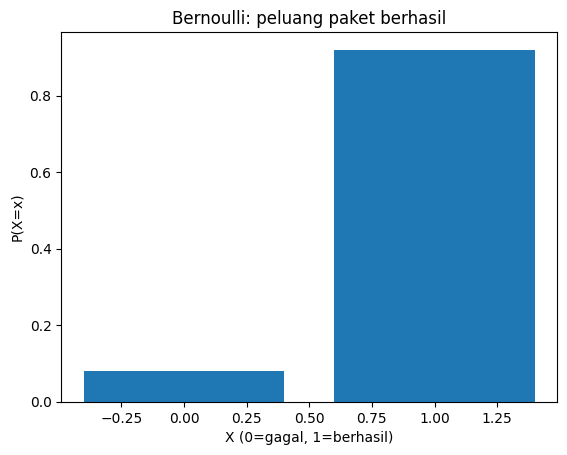

In [ ]:
X = stats.bernoulli(0.92)
print("P(X=1) =", X.pmf(1), "| P(X=0) =", X.pmf(0))
print("E[X] =", X.mean(), "| Var(X) =", X.var())
sim = np.random.binomial(1,0.92,100_000)
print("Simulasi mean =", sim.mean())

plt.bar([0,1], X.pmf([0,1]))
plt.title("Bernoulli: peluang paket berhasil")
plt.xlabel("X (0=gagal, 1=berhasil)")
plt.ylabel("P(X=x)")
plt.show()

### 5.2 D2: Distribusi Binomial pada cacat modul perangkat lunak

P(X=0) = 0.08196620357733819
P(X=2) = 0.2696052820880312
P(X<=3) = 0.7842064485762474
P(X>=5) = 0.08736154558975634
E[X] = 2.4 | Var(X) = 2.2079999999999997 | SD = 1.4859340496805367
Simulasi P(X=2) = 0.26922
Manual P(X=2) = 0.26960528208803153


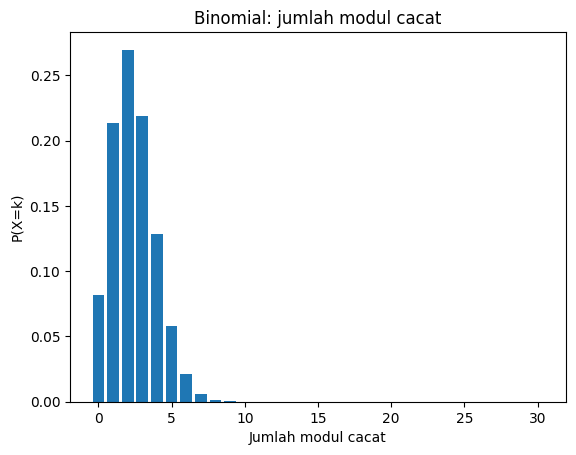

In [ ]:
X = stats.binom(30,0.08)
print("P(X=0) =", X.pmf(0))
print("P(X=2) =", X.pmf(2))
print("P(X<=3) =", X.cdf(3))
print("P(X>=5) =", X.sf(4))
print("E[X] =", X.mean(), "| Var(X) =", X.var(), "| SD =", X.std())
sim = np.random.binomial(30,0.08,500_000)
print("Simulasi P(X=2) =", np.mean(sim==2))
print("Manual P(X=2) =", math.comb(30,2)*0.08**2*0.92**28)

k = np.arange(31)
plt.bar(k,X.pmf(k))
plt.title("Binomial: jumlah modul cacat")
plt.xlabel("Jumlah modul cacat")
plt.ylabel("P(X=k)")
plt.show()

### 5.3 D3: Distribusi Geometrik pada upaya menebak PIN

P(X=1) = 0.001
P(X<=100) = 0.09520785288629095
P(X<=1000) = 0.6323045752290359
P(X<=3) = 0.0029970009999999996
E[X] = 1000.0 | Var(X) = 999000.0 | Median = 693.0
Simulasi mean = 998.798565


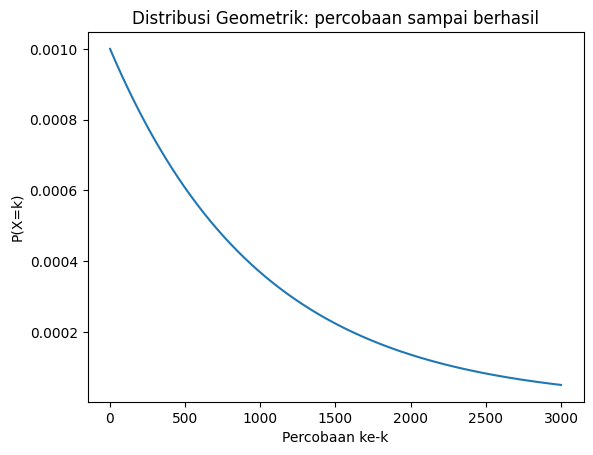

In [ ]:
X = stats.geom(0.001)
print("P(X=1) =", X.pmf(1))
print("P(X<=100) =", X.cdf(100))
print("P(X<=1000) =", X.cdf(1000))
print("P(X<=3) =", X.cdf(3))
print("E[X] =", X.mean(), "| Var(X) =", X.var(), "| Median =", X.median())
sim = np.random.geometric(0.001,200_000)
print("Simulasi mean =", sim.mean())

k = np.arange(1,3001)
plt.plot(k,X.pmf(k))
plt.title("Distribusi Geometrik: percobaan sampai berhasil")
plt.xlabel("Percobaan ke-k")
plt.ylabel("P(X=k)")
plt.show()

### 5.4 D4: Distribusi Poisson pada request per detik

P(X=0) = 0.006737946999085467
P(X=5) = 0.17546736976785068
P(X>=10) = 0.03182805730620481
E[X] = 5.0 | Var(X) = 5.0
Simulasi mean = 5.006956 | variance = 5.007539614064
Binomial(1000,0.005) P(X=5) = 0.17590761642001468


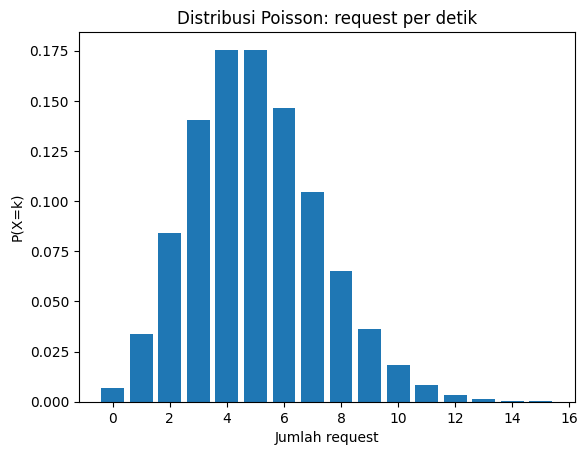

In [ ]:
X = stats.poisson(5)
print("P(X=0) =", X.pmf(0))
print("P(X=5) =", X.pmf(5))
print("P(X>=10) =", X.sf(9))
print("E[X] =", X.mean(), "| Var(X) =", X.var())
sim = np.random.poisson(5,500_000)
print("Simulasi mean =", sim.mean(), "| variance =", sim.var())
print("Binomial(1000,0.005) P(X=5) =", stats.binom(1000,0.005).pmf(5))

k = np.arange(16)
plt.bar(k,X.pmf(k))
plt.title("Distribusi Poisson: request per detik")
plt.xlabel("Jumlah request")
plt.ylabel("P(X=k)")
plt.show()

### 5.5 D5: Distribusi Eksponensial pada selang antar-request

P(T<0.1) = 0.3934693402873666
P(T>0.5) = 0.0820849986238988
E[T] = 0.2 | Var(T) = 0.04000000000000001
P(T>0.7 | T>0.2) = 0.08208499862389883
P(T>0.5) = 0.0820849986238988
Simulasi mean = 0.20000688988087054


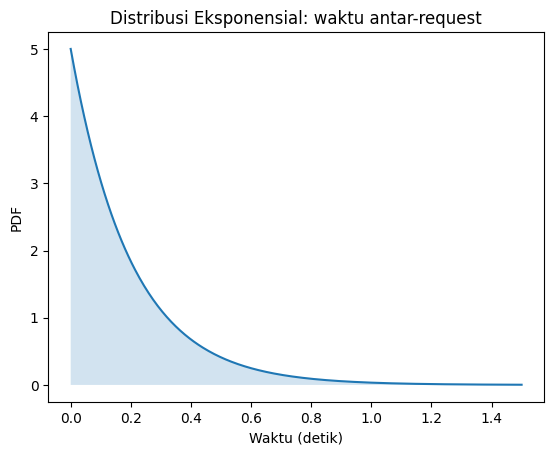

In [ ]:
X = stats.expon(scale=1/5)
print("P(T<0.1) =", X.cdf(0.1))
print("P(T>0.5) =", X.sf(0.5))
print("E[T] =", X.mean(), "| Var(T) =", X.var())
print("P(T>0.7 | T>0.2) =", X.sf(0.7)/X.sf(0.2))
print("P(T>0.5) =", X.sf(0.5))
sim = np.random.exponential(0.2,500_000)
print("Simulasi mean =", sim.mean())

t = np.linspace(0,1.5,400)
plt.plot(t,X.pdf(t))
plt.fill_between(t,X.pdf(t),alpha=0.2)
plt.title("Distribusi Eksponensial: waktu antar-request")
plt.xlabel("Waktu (detik)")
plt.ylabel("PDF")
plt.show()

### 5.6 D6: Distribusi Uniform kontinu pada jeda hop jaringan

P(X<10) = 0.25
P(12<X<20) = 0.4
E[X] = 15.0 | Var(X) = 33.33333333333333
Simulasi mean satu hop = 15.005769792262203
Simulasi variance satu hop = 33.36967424085556
Teori mean total 3 hop = 45.0
Teori variance total 3 hop = 99.99999999999999
Simulasi mean total 3 hop = 45.002434304720595
Simulasi SD total 3 hop = 9.991562195998249


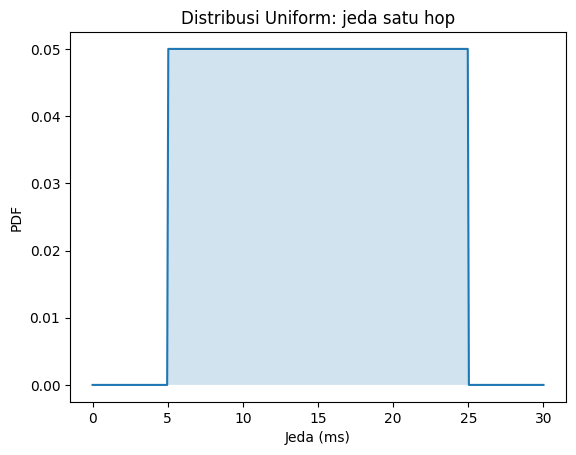

In [ ]:
X = stats.uniform(loc=5,scale=20)
print("P(X<10) =", X.cdf(10))
print("P(12<X<20) =", X.cdf(20)-X.cdf(12))
print("E[X] =", X.mean(), "| Var(X) =", X.var())

sim_hop = np.random.uniform(5,25,(300_000,3))
total = sim_hop.sum(axis=1)
print("Simulasi mean satu hop =", sim_hop[:,0].mean())
print("Simulasi variance satu hop =", sim_hop[:,0].var())
print("Teori mean total 3 hop =", 3*X.mean())
print("Teori variance total 3 hop =", 3*X.var())
print("Simulasi mean total 3 hop =", total.mean())
print("Simulasi SD total 3 hop =", total.std())

x = np.linspace(0,30,400)
plt.plot(x,X.pdf(x))
plt.fill_between(x,X.pdf(x),alpha=0.2)
plt.title("Distribusi Uniform: jeda satu hop")
plt.xlabel("Jeda (ms)")
plt.ylabel("PDF")
plt.show()

### 5.7 D7: Distribusi Normal pada latensi ujung ke ujung

P(X<100) = 0.09121121972586788
P(X>150) = 0.022750131948179195
P(105<X<135) = 0.6826894921370859
Persentil 95 = 144.67280440427209
Persentil 99 = 154.8952181106126
Simulasi P(X>150) = 0.022861
Aturan 68-95-99.7 = [np.float64(0.6826894921370859), np.float64(0.9544997361036416), np.float64(0.9973002039367398)]


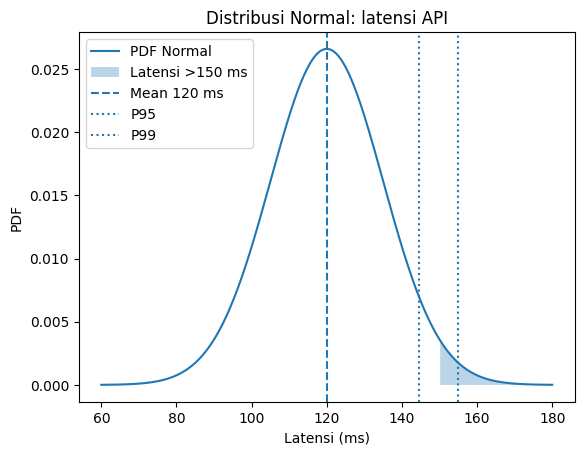

In [ ]:
X = stats.norm(loc=120,scale=15)
print("P(X<100) =", X.cdf(100))
print("P(X>150) =", X.sf(150))
print("P(105<X<135) =", X.cdf(135)-X.cdf(105))
print("Persentil 95 =", X.ppf(0.95))
print("Persentil 99 =", X.ppf(0.99))

sim = np.random.normal(120,15,1_000_000)
print("Simulasi P(X>150) =", np.mean(sim>150))
print("Aturan 68-95-99.7 =", [
    X.cdf(120+j*15)-X.cdf(120-j*15) for j in (1,2,3)
])

x = np.linspace(60,180,500)
plt.plot(x,X.pdf(x),label="PDF Normal")
plt.fill_between(x,X.pdf(x),where=(x>150),alpha=0.3,label="Latensi >150 ms")
plt.axvline(120,linestyle="--",label="Mean 120 ms")
plt.axvline(X.ppf(.95),linestyle=":",label="P95")
plt.axvline(X.ppf(.99),linestyle=":",label="P99")
plt.title("Distribusi Normal: latensi API")
plt.xlabel("Latensi (ms)")
plt.ylabel("PDF")
plt.legend()
plt.show()